In [7]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from PIL import Image

PROJECT = os.path.expanduser("~/cylinder-ml")       # корень проекта
FIG_DIR = f"{PROJECT}/figures"
os.makedirs(FIG_DIR, exist_ok=True)                 # создаст папку, если её нет

D, U = 0.001, 1.5
CD_LIT, ST_LIT = 1.33, 0.1643

OF_FILE = f"{PROJECT}/cases/cylinder_Re100_bw_sf7/postProcessing/forceCoeffsIncompressible/0/forceCoeffs.dat"
FL_CD   = "/mnt/c/fluent_cylinder/anim2/cd-run3_1_1.out"
FL_CL   = "/mnt/c/fluent_cylinder/anim2/cl-run3_1_1.out"
FL_ANIM = "/mnt/c/fluent_cylinder/anim2"

In [13]:
def read_fluent_out(path):
    """Читает .out-файл Fluent, пропуская строки-заголовки."""
    rows = []
    with open(path) as f:
        for line in f:
            try:
                rows.append([float(p) for p in line.split()])
            except ValueError:
                continue
    return np.array(rows)


def analyze(t, Cd, Cl, t_start):
    m = t > t_start
    t, Cd, Cl = t[m], Cd[m], Cl[m]
    peaks, _ = find_peaks(Cl, prominence=0.1)
    T = np.mean(np.diff(t[peaks]))                    # период — по всем пикам
    w = slice(peaks[0], peaks[-1])                    # окно: целое число периодов
    return {
        "Cd":      Cd[w].mean(),
        "St":      D / (T * U),
        "Cl_amp":  (Cl[w].max() - Cl[w].min()) / 2,
        "n_peaks": len(peaks),
    }

In [14]:
of = np.loadtxt(OF_FILE, comments="#")
t_of, Cd_of, Cl_of = of[:, 0], of[:, 2], of[:, 3]

cd_f = read_fluent_out(FL_CD)
cl_f = read_fluent_out(FL_CL)
t_fl, Cd_fl, Cl_fl = cd_f[:, 2], cd_f[:, 1], cl_f[:, 1]

# проверки: никаких inf/nan, время совпадает, диапазон разумный
for name, arr in [("Cd_fl", Cd_fl), ("Cl_fl", Cl_fl), ("Cd_of", Cd_of), ("Cl_of", Cl_of)]:
    assert np.all(np.isfinite(arr)), f"{name}: есть inf или nan!"
assert np.allclose(cd_f[:, 2], cl_f[:, 2]), "время в файлах cd и cl не совпадает"

print(f"OpenFOAM: {len(t_of)} точек, t от {t_of[0]:.4f} до {t_of[-1]:.4f} с")
print(f"Fluent:   {len(t_fl)} точек, t от {t_fl[0]:.4f} до {t_fl[-1]:.4f} с")
print(f"Fluent Cd: от {Cd_fl.min():.3f} до {Cd_fl.max():.3f}")

OpenFOAM: 36882 точек, t от 0.0000 до 0.2000 с
Fluent:   3000 точек, t от 0.2000 до 0.2600 с
Fluent Cd: от 1.308 до 1.325


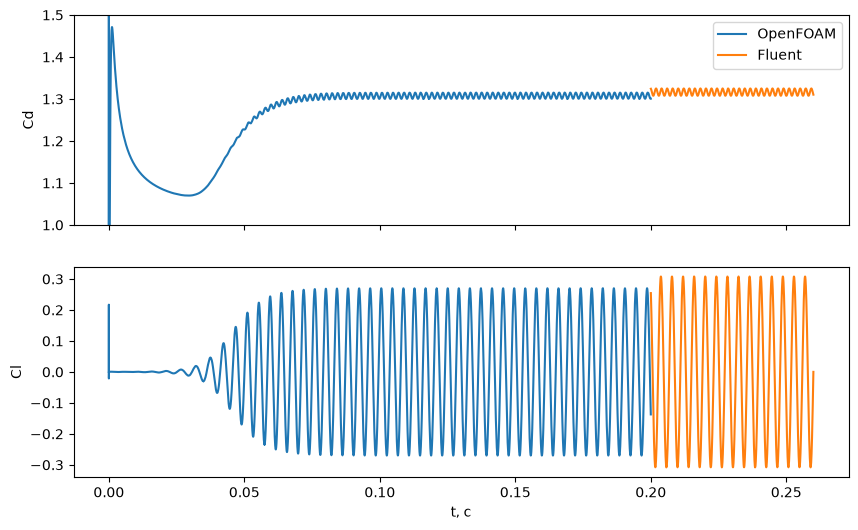

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(t_of, Cd_of, label="OpenFOAM")
ax1.plot(t_fl, Cd_fl, label="Fluent")
ax1.set_ylim(1.0, 1.5); ax1.set_ylabel("Cd"); ax1.legend()
ax2.plot(t_of, Cl_of, label="OpenFOAM")
ax2.plot(t_fl, Cl_fl, label="Fluent")
ax2.set_ylabel("Cl"); ax2.set_xlabel("t, с")
plt.show()

In [15]:
res_of = analyze(t_of, Cd_of, Cl_of, t_start=0.11)
res_fl = analyze(t_fl, Cd_fl, Cl_fl, t_start=0.2)

print(f"{'':8s} {'OpenFOAM':>10s} {'Fluent':>10s} {'разница':>9s}")
for k in ["Cd", "St", "Cl_amp"]:
    a, b = res_of[k], res_fl[k]
    print(f"{k:8s} {a:10.4f} {b:10.4f} {100 * (b - a) / a:+8.2f}%")
print(f"{'n_peaks':8s} {res_of['n_peaks']:10d} {res_fl['n_peaks']:10d}")

print(f"\nОтносительно литературы:")
for name, r in [("OpenFOAM", res_of), ("Fluent", res_fl)]:
    print(f"{name:9s} Cd {100 * (r['Cd'] - CD_LIT) / CD_LIT:+.2f}%   "
          f"St {100 * (r['St'] - ST_LIT) / ST_LIT:+.2f}%")

           OpenFOAM     Fluent   разница
Cd           1.3078     1.3163    +0.65%
St           0.1631     0.1629    -0.13%
Cl_amp       0.2701     0.3082   +14.11%
n_peaks          22         14

Относительно литературы:
OpenFOAM  Cd -1.67%   St -0.72%
Fluent    Cd -1.03%   St -0.85%


FileNotFoundError: [Errno 2] No such file or directory: '../figures/code_to_code_Cl.png'

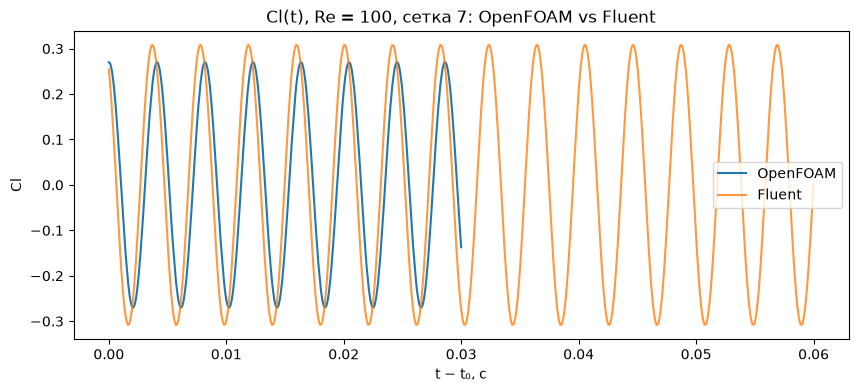

In [ ]:
m_of = t_of > 0.17
plt.figure(figsize=(10, 4))
plt.plot(t_of[m_of] - t_of[m_of][0], Cl_of[m_of], label="OpenFOAM")
plt.plot(t_fl - t_fl[0], Cl_fl, label="Fluent", alpha=0.8)
plt.xlabel("t − t₀, с"); plt.ylabel("Cl")
plt.title("Cl(t), Re = 100, сетка 7: OpenFOAM vs Fluent")
plt.legend()
plt.savefig(f"{FIG_DIR}/code_to_code_Cl.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
files = sorted(glob.glob(f"{FL_ANIM}/*.png"),
               key=lambda f: int(re.findall(r"\d+", os.path.basename(f))[-1]))
print(len(files), "кадров")

frames = [Image.open(f) for f in files]
frames = [fr.resize((fr.width // 2, fr.height // 2)) for fr in frames]
frames[0].save(f"{FIG_DIR}/fluent_vortex_street.gif",
               save_all=True, append_images=frames[1:], duration=60, loop=0)

200 кадров


In [6]:
print("ноутбук запущен из:", os.getcwd())
print(glob.glob(os.path.expanduser("~/cylinder-ml/cases/*")))
print(glob.glob(os.path.expanduser("~/cylinder-ml/cases/cylinder_Re100_bw_sf7/postProcessing/*/*/*.dat")))

ноутбук запущен из: /home/rvstxm/notebooks
['/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf3', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf5', '/home/rvstxm/cylinder-ml/cases/cylinder', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf9', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf7', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100']
['/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf7/postProcessing/residuals/0/residuals.dat', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf7/postProcessing/forceCoeffsIncompressible/0/forceCoeffs.dat', '/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf7/postProcessing/forcesIncompressible/0/forces.dat']
